결혼식장에서 참석인원이 식사를 하고 가는 사람을 파악해서 음식준비를 하려함

1.참석인원(total),식사인원(reception)을 학습하여 참석 300명 일때 식사인원을 예측하시오.

2.산점도그래프와 직선그래프를 출력하시오.

data-> QuizData.csv

In [61]:
import matplotlib.pyplot as plt    
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'   
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd                                               
import numpy as np                                         
from sklearn import svm,metrics                            
from sklearn.neighbors import KNeighborsClassifier   #분류
from sklearn.neighbors import KNeighborsRegressor    #예측
from sklearn.linear_model import LinearRegression    #예측
from sklearn.metrics import mean_absolute_error      #평균절대값오차 오차범위     
from sklearn.preprocessing import StandardScaler     #정규화 클래스 
from sklearn.model_selection import train_test_split  

In [62]:
df = pd.read_csv('data/QuizData.csv')
df.head(5)

,total,reception
0,118,62
1,253,148
2,320,201
3,94,80
4,155,92


In [71]:
#데이터 전처리 ->2차원배열이여야 테스트 가능
data = df.iloc[:,0].values
#data = df.iloc[:,:-1].values  #2차원 가져오기
label =df.iloc[:,1:].values

In [72]:
data =df.iloc[:,0].values
data.reshape(-1,1)[:2]

array([[118],
       [253]])

In [64]:
#데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label)

In [ ]:
#데이터학습
lr = LinearRegression()
lr.fit(train_data,train_label)    #fit안에는 2차원 배열만 들어갈 수 있음

#테스트데이터 예측
predict = lr.predict(test_data)
print("예측인원: ", predict)

#정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print("train정확도:",score)
print("test정확도:",score2)


예측인원:  [[156.10116283]
 [139.26041719]
 [234.12995098]
 [126.91053705]
 [114.56065691]]
train정확도: 0.8899464818765943
test정확도: 0.5878223868587993


In [66]:
#참석인원 입력
in_data = input("참석인원을 입력하세요.(예: 300)")
in_data =float(in_data)
result = lr.predict([[in_data]])
print("예측 식사인원:",result)

예측 식사인원: [[182.48499767]]


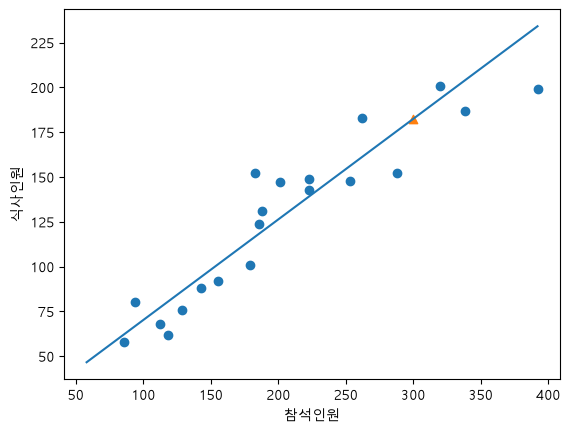

In [ ]:
# 산점도 그래프/plot->lr.coef_,lr.intercept_
plt.scatter(data,label)
plt.scatter(in_data,result,marker="^")

plt.plot([58,392],[58*lr.coef_[0]+lr.intercept_,392*lr.coef_[0]+lr.intercept_])
plt.xlabel("참석인원")
plt.ylabel("식사인원")
plt.show()